# Tugas 3: *Multiprocessing*

## Latihan 1. Analisis *Speedup* Skala pada *Multiprocessing*

In [ ]:
from pathlib import Path

_ = Path("modul_t1.py").write_text("""
def hitung_prima(n):
    jumlah_prima = 0
    for angka in range(2, n + 1):
        prima = True
        for i in range(2, int(angka ** 0.5) + 1):
            if angka % i == 0:
                prima = False
                break
        if prima:
            jumlah_prima += 1
    return jumlah_prima
""".lstrip("\n"), encoding="utf-8")

**Penjelasan.** Fungsi `hitung_prima` menguji tiap angka dengan pembagi sampai akar angka tersebut. Beban ini murni CPU-*bound*, sehingga cocok untuk menguji *multiprocessing*.

In [ ]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import multiprocessing as mp
import statistics
import time
import matplotlib.pyplot as plt
from modul_t1 import hitung_prima

n = 200000
TOTAL_TUGAS = 8
jumlah_worker = [1, 2, 4, 8]
ctx = mp.get_context("spawn")

print("Jumlah core logis pada komputer ini:", os.cpu_count())

ULANGAN = 3
catatan = {w: [] for w in jumlah_worker}
for putaran in range(ULANGAN):
    for worker in jumlah_worker:         
        mulai = time.perf_counter()
        with ctx.Pool(processes=worker) as pool:
            hasil = pool.map(hitung_prima, [n] * TOTAL_TUGAS)
        catatan[worker].append(time.perf_counter() - mulai)
    print(f"Putaran {putaran + 1}/{ULANGAN} selesai")

waktu = [statistics.median(catatan[w]) for w in jumlah_worker]
for w, t in zip(jumlah_worker, waktu):
    print(f"Worker = {w}, Waktu (median {ULANGAN} kali) = {t:.4f} detik")

print("Semua hasil sama:", len(set(hasil)) == 1, "| jumlah prima sampai n:", hasil[0])

Jumlah core logis pada komputer ini: 1


Putaran 1/3 selesai


Putaran 2/3 selesai


Putaran 3/3 selesai
Worker = 1, Waktu (median 3 kali) = 2.3051 detik
Worker = 2, Waktu (median 3 kali) = 2.3299 detik
Worker = 4, Waktu (median 3 kali) = 2.5839 detik
Worker = 8, Waktu (median 3 kali) = 2.8062 detik
Semua hasil sama: True | jumlah prima sampai n: 17984


**Penjelasan.** Setiap jumlah *worker* diuji 3 kali secara bergantian dan diambil median, supaya satu lonjakan sesaat pada sistem tidak mengubah hasil. Waktu diukur dari pembuatan `Pool` sampai `map` selesai, sehingga biaya pembuatan proses (*spawn*) ikut terhitung sebagai *overhead* nyata. Pemeriksaan `set(hasil)` memastikan semua *worker* menghasilkan jawaban yang sama.

In [3]:
waktu_1 = waktu[0]
speedup = [waktu_1 / t for t in waktu]

P = 1
speedup_amdahl = [1 / ((1 - P) + (P / w)) for w in jumlah_worker]

print(f"{'Worker':>7} {'Waktu (s)':>10} {'Speedup':>9} {'Ideal':>7} {'Efisiensi':>10}")
for w, t, s, a in zip(jumlah_worker, waktu, speedup, speedup_amdahl):
    print(f"{w:>7} {t:>10.4f} {s:>8.2f}x {a:>6.2f}x {s / w:>9.0%}")

print("\nEstimasi fraksi paralel (p) dari data, S = 1 / ((1 - p) + p / N):")
for w, s in zip(jumlah_worker[1:], speedup[1:]):
    if s <= 1:
        print(f"  N = {w}  S = {s:5.2f}x  ->  tidak ada percepatan (p tidak dapat diestimasi)")
    else:
        p = (1 - 1 / s) / (1 - 1 / w)
        print(f"  N = {w}  S = {s:5.2f}x  ->  p = {p:5.2f}")

 Worker  Waktu (s)   Speedup   Ideal  Efisiensi
      1     2.3051     1.00x   1.00x      100%
      2     2.3299     0.99x   2.00x       49%
      4     2.5839     0.89x   4.00x       22%
      8     2.8062     0.82x   8.00x       10%

Estimasi fraksi paralel (p) dari data, S = 1 / ((1 - p) + p / N):
  N = 2  S =  0.99x  ->  tidak ada percepatan (p tidak dapat diestimasi)
  N = 4  S =  0.89x  ->  tidak ada percepatan (p tidak dapat diestimasi)
  N = 8  S =  0.82x  ->  tidak ada percepatan (p tidak dapat diestimasi)


**Penjelasan.** *Speedup* aktual dihitung sebagai waktu 1 *worker* dibagi waktu *worker* lain. Kolom *Ideal* memakai Hukum Amdahl dengan P = 1 (seluruh program dianggap paralel), sehingga hasilnya linear. Fraksi paralel p yang diestimasi dari data nyata biasanya di bawah 1 karena ada bagian serial dan *overhead*.

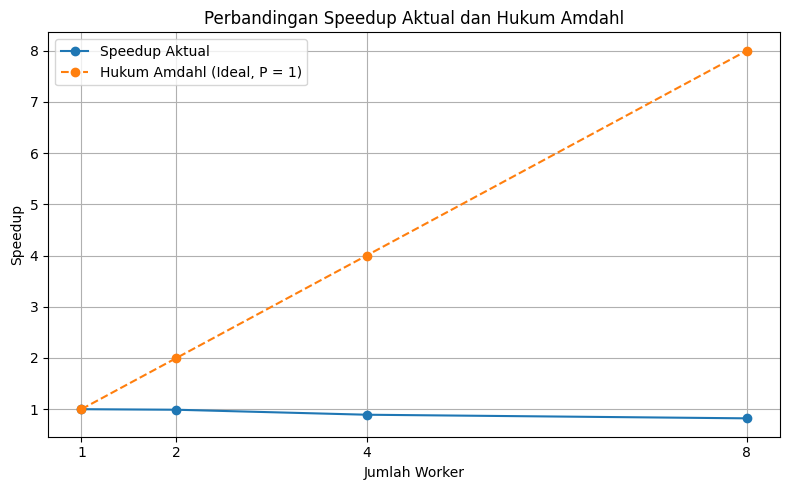

In [4]:
plt.figure(figsize=(8, 5))
plt.plot(jumlah_worker, speedup, marker="o", label="Speedup Aktual")
plt.plot(jumlah_worker, speedup_amdahl, marker="o", linestyle="--", label="Hukum Amdahl (Ideal, P = 1)")
plt.xlabel("Jumlah Worker")
plt.ylabel("Speedup")
plt.title("Perbandingan Speedup Aktual dan Hukum Amdahl")
plt.xticks(jumlah_worker)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
core = os.cpu_count()
terbaik = jumlah_worker[waktu.index(min(waktu))]
print(f"Komputer ini memiliki {core} core logis.")
print(f"Waktu tercepat dicapai pada {terbaik} worker (speedup {max(speedup):.2f}x).")
lebih = [w for w in jumlah_worker if w > core]
if lebih:
    print(f"Worker {lebih} melebihi jumlah core, sehingga proses harus berbagi core "
          f"dan penambahan worker tidak lagi mempercepat program.")
else:
    print("Seluruh jumlah worker yang diuji masih berada dalam jumlah core yang tersedia.")

Komputer ini memiliki 1 core logis.
Waktu tercepat dicapai pada 1 worker (speedup 1.00x).
Worker [2, 4, 8] melebihi jumlah core, sehingga proses harus berbagi core dan penambahan worker tidak lagi mempercepat program.


**Analisis.** Secara teori, penambahan *worker* mempercepat program. Garis Hukum Amdahl dengan P = 1 menghasilkan *speedup* ideal 1x, 2x, 4x, dan 8x. Hasil aktual hampir selalu berada di bawah garis itu karena tiga hal: (1) *overhead* pembuatan proses dan pengiriman tugas, (2) bagian program yang tetap serial (pembuatan `Pool`, pengumpulan hasil), dan (3) jumlah *core* fisik yang terbatas. *Speedup* hanya bisa naik sampai jumlah *worker* menyamai jumlah *core*; di atas itu proses saling berebut *core* sehingga waktu tidak lagi turun, bahkan bisa naik karena *context switching*.

**Kesimpulan.** Memperbanyak *worker* tidak selalu mempercepat program. *Speedup* aktual berbeda dari ideal Hukum Amdahl akibat *overhead* *multiprocessing* dan keterbatasan sumber daya komputer. Sel terakhir di atas mencetak jumlah *core* dan *worker* terbaik pada komputer yang menjalankan notebook ini.

## 2. *Shared Memory* vs *Message Passing*

In [ ]:
from pathlib import Path

_ = Path("modul_t2.py").write_text("""
import random

JUMLAH_ANGKA = 1_000_000

def proses_queue(queue, seed):
    random.seed(seed)
    subtotal = 0.0
    for _ in range(JUMLAH_ANGKA):
        subtotal += random.random()
    queue.put(subtotal)

def proses_shared_value(nilai, lock, seed):
    random.seed(seed)
    subtotal = 0.0
    for _ in range(JUMLAH_ANGKA):
        subtotal += random.random()
    with lock:
        nilai.value += subtotal
""".lstrip("\n"), encoding="utf-8")

**Penjelasan.** Perhitungan subtotal dikerjakan secara lokal di tiap proses, lalu hanya satu angka yang dikomunikasikan. Pada versi `Value`, bagian `with lock` melindungi operasi `nilai.value += subtotal` yang bukan operasi atomik (baca, tambah, tulis), sehingga mencegah *race condition*.

In [ ]:
import multiprocessing as mp
import statistics
import time
from modul_t2 import proses_queue, proses_shared_value, JUMLAH_ANGKA

JUMLAH_PROSES = 4
ctx = mp.get_context("spawn")


def jalankan_queue():
    queue = ctx.Queue()
    proses = []
    mulai = time.perf_counter()
    for i in range(JUMLAH_PROSES):
        p = ctx.Process(target=proses_queue, args=(queue, 100 + i))
        proses.append(p)
        p.start()
    total = 0.0
    for _ in range(JUMLAH_PROSES):
        total += queue.get()
    for p in proses:
        p.join()
    return total, time.perf_counter() - mulai


def jalankan_shared_value():
    nilai = ctx.Value("d", 0.0)
    lock = ctx.Lock()
    proses = []
    mulai = time.perf_counter()
    for i in range(JUMLAH_PROSES):
        p = ctx.Process(target=proses_shared_value, args=(nilai, lock, 100 + i))
        proses.append(p)
        p.start()
    for p in proses:
        p.join()
    return nilai.value, time.perf_counter() - mulai


print(f"Jumlah proses     : {JUMLAH_PROSES}")
print(f"Angka per proses  : {JUMLAH_ANGKA:,}")
print(f"Total angka       : {JUMLAH_PROSES * JUMLAH_ANGKA:,}")

ULANGAN = 3
daftar_q, daftar_s = [], []
for putaran in range(ULANGAN):           
    total_queue, w = jalankan_queue()
    daftar_q.append(w)
    total_shared, w = jalankan_shared_value()
    daftar_s.append(w)
    print(f"Putaran {putaran + 1}/{ULANGAN} selesai")

waktu_queue = statistics.median(daftar_q)
waktu_shared = statistics.median(daftar_s)

print("\n--- Versi 1: Queue (Message Passing) ---")
print(f"Total hasil       : {total_queue:.6f}")
print(f"Waktu eksekusi    : {waktu_queue:.4f} detik (median {ULANGAN} kali)")

print("\n--- Versi 2: Value + Lock (Shared Memory) ---")
print(f"Total hasil       : {total_shared:.6f}")
print(f"Waktu eksekusi    : {waktu_shared:.4f} detik (median {ULANGAN} kali)")

Jumlah proses     : 4
Angka per proses  : 1,000,000
Total angka       : 4,000,000


Putaran 1/3 selesai


Putaran 2/3 selesai


Putaran 3/3 selesai

--- Versi 1: Queue (Message Passing) ---
Total hasil       : 1999974.193513
Waktu eksekusi    : 0.4083 detik (median 3 kali)

--- Versi 2: Value + Lock (Shared Memory) ---
Total hasil       : 1999974.193513
Waktu eksekusi    : 0.4128 detik (median 3 kali)


**Penjelasan.** Pembacaan `queue.get()` ditempatkan sebelum `join()` karena dokumentasi Python menyarankan data di `Queue` dikonsumsi lebih dulu agar proses anak tidak tertahan saat membuang isi antreannya. Untuk satu angka kecil ini risikonya rendah, tetapi urutan tersebut adalah praktik yang lebih aman.

In [8]:
print(f"{'Metode':<22} {'Waktu (s)':>10}")
print(f"{'Queue':<22} {waktu_queue:>10.4f}")
print(f"{'Value + Lock':<22} {waktu_shared:>10.4f}")

selisih = abs(waktu_queue - waktu_shared) / max(waktu_queue, waktu_shared) * 100
if waktu_queue < waktu_shared:
    print(f"\nQueue lebih cepat sekitar {selisih:.1f}%.")
elif waktu_shared < waktu_queue:
    print(f"\nValue + Lock lebih cepat sekitar {selisih:.1f}%.")
else:
    print("\nKedua metode memiliki waktu yang sama.")

print("Total kedua metode sama (toleransi 1e-6):", abs(total_queue - total_shared) < 1e-6)

Metode                  Waktu (s)
Queue                      0.4083
Value + Lock               0.4128

Queue lebih cepat sekitar 1.1%.
Total kedua metode sama (toleransi 1e-6): True


**Analisis.** Pada metode `Queue`, setiap proses mengirim subtotal ke proses utama, yang kemudian menjumlahkannya. Pada metode `Value` + `Lock`, setiap proses menambahkan subtotal langsung ke memori bersama, dan `Lock` memastikan hanya satu proses yang mengubah nilai pada satu waktu. Dalam program ini, kedua metode hanya berkomunikasi **satu kali per proses**, sedangkan hampir seluruh waktu dipakai untuk menghitung 1 juta angka acak. Akibatnya, selisih waktu antarmetode kecil dan lebih dipengaruhi variasi sistem (penjadwalan proses, biaya *spawn*) daripada perbedaan mekanisme komunikasi. Perbedaan baru terasa jika komunikasi dilakukan jauh lebih sering, misalnya memperbarui `Value` di setiap iterasi, yang membuat `Lock` menjadi titik rebutan.

**Kesimpulan.** `Queue` memakai *message passing* sehingga data dikirim dari proses ke proses utama, sedangkan `Value` + `Lock` memakai *shared memory* dengan perlindungan `Lock`. Metode yang lebih cepat ditunjukkan oleh sel perbandingan di atas, dan selisihnya dapat berubah-ubah antarpercobaan karena kecilnya biaya komunikasi dibanding komputasi. Kedua metode menghasilkan total yang sama, yang menandakan implementasinya benar.

## 3. *Producer-Consumer* Antar-Proses (CPU-*bound*): *Multiprocessing* vs *Threading*

In [ ]:
from pathlib import Path

_ = Path("modul_t3.py").write_text("""
JUMLAH_CONSUMER = 2
JUMLAH_TUGAS_PER_PRODUCER = 20
BATAS_PRIMA_AWAL = 20000


def hitung_prima(n):
    jumlah = 0
    for angka in range(2, n + 1):
        prima = True
        for pembagi in range(2, int(angka ** 0.5) + 1):
            if angka % pembagi == 0:
                prima = False
                break
        if prima:
            jumlah += 1
    return jumlah


def producer(producer_id, task_queue):
    for i in range(JUMLAH_TUGAS_PER_PRODUCER):
        nilai = BATAS_PRIMA_AWAL + (i * 100) + (producer_id * 50)
        task_queue.put(nilai)


def consumer(task_queue, result_queue):
    jumlah_tugas = 0
    total_hasil = 0
    while True:
        tugas = task_queue.get()
        if tugas is None:          # sinyal berhenti
            break
        total_hasil += hitung_prima(tugas)
        jumlah_tugas += 1
    result_queue.put((jumlah_tugas, total_hasil))
""".lstrip("\n"), encoding="utf-8")

**Penjelasan.** Satu set fungsi `producer` dan `consumer` dipakai untuk kedua versi, sehingga satu-satunya perbedaan adalah jenis *worker* (proses atau *thread*) dan jenis antrean. Dengan begitu perbandingan waktu adil.

In [ ]:
import multiprocessing as mp
import os
import queue
import statistics
import threading
import time
from modul_t3 import (producer, consumer, JUMLAH_CONSUMER,
                      JUMLAH_TUGAS_PER_PRODUCER)

JUMLAH_PRODUCER = 2
ctx = mp.get_context("spawn")


def jalankan(kelas_worker, task_queue, result_queue):
    producers, consumers = [], []
    mulai = time.perf_counter()

    for _ in range(JUMLAH_CONSUMER):
        w = kelas_worker(target=consumer, args=(task_queue, result_queue))
        consumers.append(w)
        w.start()
    for i in range(JUMLAH_PRODUCER):
        w = kelas_worker(target=producer, args=(i, task_queue))
        producers.append(w)
        w.start()

    for w in producers:
        w.join()
    for _ in range(JUMLAH_CONSUMER):
        task_queue.put(None)

    jumlah_tugas, total_hasil = 0, 0
    for _ in range(JUMLAH_CONSUMER):
        j, h = result_queue.get()
        jumlah_tugas += j
        total_hasil += h
    for w in consumers:
        w.join()

    waktu = time.perf_counter() - mulai
    return waktu, jumlah_tugas, total_hasil


print(f"Jumlah producer           : {JUMLAH_PRODUCER}")
print(f"Jumlah consumer           : {JUMLAH_CONSUMER}")
print(f"Tugas per producer        : {JUMLAH_TUGAS_PER_PRODUCER}")
print(f"Total tugas               : {JUMLAH_PRODUCER * JUMLAH_TUGAS_PER_PRODUCER}\n")

ULANGAN = 3
daftar_mp, daftar_th = [], []
for putaran in range(ULANGAN):            
    w, tugas_mp, hasil_mp = jalankan(ctx.Process, ctx.Queue(), ctx.Queue())
    daftar_mp.append(w)
    w, tugas_th, hasil_th = jalankan(threading.Thread, queue.Queue(), queue.Queue())
    daftar_th.append(w)
    print(f"Putaran {putaran + 1}/{ULANGAN} selesai")

waktu_mp = statistics.median(daftar_mp)
waktu_th = statistics.median(daftar_th)

print("\nVERSI 1: MULTIPROCESSING")
print(f"Jumlah tugas diproses : {tugas_mp}")
print(f"Total hasil           : {hasil_mp}")
print(f"Waktu eksekusi        : {waktu_mp:.4f} detik (median {ULANGAN} kali)")
print("\nVERSI 2: THREADING")
print(f"Jumlah tugas diproses : {tugas_th}")
print(f"Total hasil           : {hasil_th}")
print(f"Waktu eksekusi        : {waktu_th:.4f} detik (median {ULANGAN} kali)")

Jumlah producer           : 2
Jumlah consumer           : 2
Tugas per producer        : 20
Total tugas               : 40



Putaran 1/3 selesai


Putaran 2/3 selesai


Putaran 3/3 selesai

VERSI 1: MULTIPROCESSING
Jumlah tugas diproses : 40
Total hasil           : 94414
Waktu eksekusi        : 0.9374 detik (median 3 kali)

VERSI 2: THREADING
Jumlah tugas diproses : 40
Total hasil           : 94414
Waktu eksekusi        : 0.6718 detik (median 3 kali)


**Penjelasan.** Fungsi `jalankan` menerima kelas *worker* (`Process` atau `Thread`) dan jenis antrean yang sesuai, sehingga logika *producer-consumer* tidak ditulis dua kali. Hasil *consumer* dibaca sebelum `join()` untuk menghindari kemungkinan *deadlock* pada `multiprocessing.Queue`.

In [11]:
speedup = waktu_th / waktu_mp
print("PERBANDINGAN PERFORMA")
print(f"Multiprocessing : {waktu_mp:.4f} detik")
print(f"Threading       : {waktu_th:.4f} detik")
print(f"Speedup multiprocessing terhadap threading : {speedup:.2f}x")

if waktu_mp < waktu_th:
    print("Hasil: multiprocessing lebih cepat daripada threading.")
elif waktu_th < waktu_mp:
    print("Hasil: threading lebih cepat daripada multiprocessing.")
else:
    print("Hasil: kedua metode memiliki waktu yang sama.")

print("Hasil perhitungan kedua versi sama:", (tugas_mp, hasil_mp) == (tugas_th, hasil_th))

core = os.cpu_count()
print(f"\nJumlah core logis: {core}")
if waktu_mp < waktu_th:
    print("Multiprocessing lebih cepat: dua consumer proses berjalan paralel di core berbeda, "
          "sedangkan thread dibatasi GIL.")
elif core is not None and core < 2:
    print("Threading lebih cepat karena komputer hanya memiliki satu core, sehingga paralelisme "
          "proses tidak dapat terjadi dan overhead pembuatan proses menjadi beban tambahan.")
else:
    print("Threading lebih cepat pada pengujian ini: biaya pembuatan proses (spawn) dan serialisasi "
          "antrean lebih besar daripada keuntungan paralelisme untuk ukuran tugas ini.")

PERBANDINGAN PERFORMA
Multiprocessing : 0.9374 detik
Threading       : 0.6718 detik
Speedup multiprocessing terhadap threading : 0.72x
Hasil: threading lebih cepat daripada multiprocessing.
Hasil perhitungan kedua versi sama: True

Jumlah core logis: 1
Threading lebih cepat karena komputer hanya memiliki satu core, sehingga paralelisme proses tidak dapat terjadi dan overhead pembuatan proses menjadi beban tambahan.


**Analisis.** Pola *producer-consumer* diterapkan dengan `Queue`: *producer* membuat tugas, *consumer* mengambil dan menghitungnya. Beban yang dipakai (menghitung bilangan prima) adalah CPU-*bound*. Pada versi *multiprocessing*, setiap *producer* dan *consumer* adalah proses terpisah dengan memori sendiri, sehingga dua *consumer* dapat berjalan paralel di *core* berbeda. Pada versi *threading*, semua *thread* berada dalam satu proses Python dan dibatasi *Global Interpreter Lock* (GIL), sehingga hanya satu *thread* yang menjalankan *bytecode* Python pada satu waktu. Karena itu, dua *consumer* *thread* tidak benar-benar paralel untuk kode CPU-*bound*.

Walaupun demikian, hasil waktu aktual bergantung pada spesifikasi komputer. *Multiprocessing* menanggung biaya pembuatan proses (*spawn*) dan serialisasi data antrean, jadi keunggulannya baru jelas bila beban per tugas cukup besar dan komputer punya minimal dua *core*. Pada komputer dengan satu *core*, atau beban yang terlalu kecil, *threading* bahkan bisa lebih cepat.

**Kesimpulan.** *Multiprocessing* lebih sesuai untuk pekerjaan CPU-*bound* karena setiap proses dapat berjalan di *core* berbeda, sedangkan *threading* lebih cocok untuk pekerjaan I/O-*bound* seperti membaca berkas atau menunggu respons jaringan. Metode yang lebih cepat pada komputer ini, beserta alasannya, dicetak oleh sel perbandingan di atas.

## 4. Refleksi: `Manager()` vs `Value`/`Array`

Saya akan memilih `Manager()` jika membuat program yang membutuhkan beberapa proses untuk berbagi data dengan struktur yang lebih kompleks, misalnya *list* atau *dict*. `Manager` lebih mudah digunakan karena data dapat diakses dan dimodifikasi oleh beberapa proses tanpa harus mengatur *shared memory* secara langsung. Namun, kemudahannya memiliki konsekuensi berupa performa yang lebih rendah karena komunikasi dengan `Manager` membutuhkan proses tambahan.

Sebaliknya, saya akan memilih `Value`/`Array` jika data yang dibagikan sederhana dan membutuhkan performa yang lebih tinggi, misalnya menyimpan angka atau kumpulan nilai dengan ukuran tertentu. `Value`/`Array` lebih cepat karena menggunakan *shared memory* secara langsung, tetapi penggunaannya lebih terbatas dan membutuhkan perhatian terhadap sinkronisasi seperti `Lock`.

Jadi, `Manager` lebih cocok ketika kemudahan penggunaan menjadi prioritas, sedangkan `Value`/`Array` lebih cocok ketika performa menjadi prioritas.